In [4]:
import numpy as np
import pandas as pd
import scipy.io
import matplotlib.pyplot as plt
import math

In [5]:
# alpha parameter = 1 eta = 10, run on 5171 trajectories, 800 iterations of MH algo 
sol = scipy.io.loadmat('./alpha_1_5000_eta_10_800.mat')

In [6]:
sol_struct = sol['sol']
maxCl = sol_struct[0,0]

In [7]:
#print(maxCl['belongTo'])
maxCl['belongTo'] = np.squeeze(maxCl['belongTo'])
print(maxCl['belongTo'])

[3 3 3 ... 9 3 3]


In [8]:
print(maxCl['weight'])

[[-0.54699463  0.59787794 -0.4493696  -0.54928048  0.20089362 -0.44658843
  -0.21487904 -0.32250666  0.90784895 -0.80988539  0.75603758]
 [-0.94663083  0.40282651 -0.19490694 -0.07355789  0.02266339  0.11995964
   0.54333093  0.52727485  0.8807908   0.37945782  0.39154315]
 [-0.27877732  0.12271832 -0.14349068  0.63016638  0.41589398  0.60712128
  -0.19010258  0.70277687  0.96157334  0.607764   -0.94516391]
 [-0.22630764  0.37252508  0.35515764 -0.55953285  0.08925681 -0.88214324
  -0.64074043  0.73618284  0.19868467  0.12600709 -0.87084257]
 [ 0.28502427  0.58767926  0.26734643 -0.20385731  0.33438669 -0.81949451
  -0.53638667  0.85359599  0.01538425  0.06605314 -0.03039008]
 [ 0.27583298  0.71164868  0.20389105 -0.66239586  0.57155947 -0.75049923
  -0.97232026  0.78585421 -0.00583522 -0.57961908 -0.45835575]]


In [9]:
reward_func = maxCl['weight']
reward_reshape = reward_func.T
print(reward_reshape)

[[-0.54699463 -0.94663083 -0.27877732 -0.22630764  0.28502427  0.27583298]
 [ 0.59787794  0.40282651  0.12271832  0.37252508  0.58767926  0.71164868]
 [-0.4493696  -0.19490694 -0.14349068  0.35515764  0.26734643  0.20389105]
 [-0.54928048 -0.07355789  0.63016638 -0.55953285 -0.20385731 -0.66239586]
 [ 0.20089362  0.02266339  0.41589398  0.08925681  0.33438669  0.57155947]
 [-0.44658843  0.11995964  0.60712128 -0.88214324 -0.81949451 -0.75049923]
 [-0.21487904  0.54333093 -0.19010258 -0.64074043 -0.53638667 -0.97232026]
 [-0.32250666  0.52727485  0.70277687  0.73618284  0.85359599  0.78585421]
 [ 0.90784895  0.8807908   0.96157334  0.19868467  0.01538425 -0.00583522]
 [-0.80988539  0.37945782  0.607764    0.12600709  0.06605314 -0.57961908]
 [ 0.75603758  0.39154315 -0.94516391 -0.87084257 -0.03039008 -0.45835575]]


In [10]:
policies = maxCl['policy']
policies = policies.T
np.shape(policies)

(11, 750)

In [8]:
mimic = pd.read_csv("./dataSets/Sepsis_data_process.csv")
demo_states = np.load("./dataSets/demonstrations_states_sample.npy")
demo_actions = np.load("./dataSets/demonstrations_actions_sample.npy")


In [9]:
tupleToNumericStates = {}
numericStatesToTuple = {}
count = 0
for i in range(25):
    for j in range(30):
        tupleToNumericStates[(i,j)] = count
        numericStatesToTuple[count] = (i,j)
        count += 1


In [10]:
print(demo_actions[5])
print(demo_states[5])

[ 62. 303. 182. 212. 212. 212. 182. 183. 151. 151. 181. 181. 181. 211.
 181. 181. 181. 183. 211. 151. 131.]
[ 62. 303. 182. 212. 212. 212. 182. 183. 151. 151. 181. 181. 181. 211.
 181. 181. 181. 183. 211. 151. 131.]


In [11]:
Qcells = maxCl['Qcells']

In [12]:
# recreate the original mimic table
def recreateOriginalTable(demonstrations, learnt_policy):
    icuids = list(map(lambda x: x[20], demonstrations))
    
    mimic_new = mimic[mimic['icustayid'].isin(icuids)]
    
    return mimic_new, len(icuids)


In [16]:

# def mapActions(mimic_table, learnt_policy):
#     actions = []
#     for i in range(len(mimic_table)):
#         curr_state = mimic_table.iloc[i]['discrete_states']
#         action_for_state = learnt_policy[int(curr_state)]
#         action_for_state -= 1
#         actions.append(action_for_state)
#     mimic_table['piL'] = actions

In [13]:
# Compute the probability distribution of actions for each state
action_distr = {}
for i in range(len(mimic)):
    state = mimic.iloc[i]['discrete_states']
    action = mimic.iloc[i]['actions']
    
    if state not in action_distr:
        action_distr[state] = [0 for i in range(25)]
    
    action_distr[state][int(action)] += 1

# normalise action distribution values
for state in action_distr:
    tot = np.sum(action_distr[state])
    vals = [x/tot for x in action_distr[state]]
    action_distr[state] = vals

In [14]:
class ClusterObject:
    def __init__(self, index, size, table, reward_function, Q_vals):
        self.no_trajs = size
        self.clusterId = index
        self.table = table
        self.reward = reward_function
        self.feature_count = self.calculateRewards()
        self.Q_vals = Q_vals
        self.action_distr = self.computeActionDistr()
        self.policyMatch = self.calculatePolicyMatching()
        self.statistics_sofa, self.statistics_AL = self.statistics()
        self.state_distr = self.compute_state_distribution()


    def compute_state_distribution(self):
        states = [i for i in range(750)]
        state_dct = dict((state,0) for state in states)
        for i in range(len(self.table)):
            state = int(self.table.iloc[i]['discrete_states'])
            # add one more time visited this state
            state_dct[state] += 1
        return state_dct
        
        
        
    def calculatePolicyMatching(self):
        states = []
        tot = len(self.table)
        matches = 0
        for i in range(len(self.table)):
            state = int(self.table.iloc[i]['discrete_states'])
            actionsE = self.table.iloc[i]['actions']
            states.append(state)
        states = np.unique(states)
        
        state_dct = {}
        
        for state in states:
            # log likelihood values of Q
            Q_s_a = self.Q_vals[state]

            # how many top 3 Q values match with expert top 3 action
            state_dct[state] = 0

            # get top 3 log likelihoods for learnt policy
            log_likelihoods_and_actions_L = sorted( [(x,i) for (i,x) in enumerate(Q_s_a)], reverse=True )[:3]
            # find top 3 log likelihoods for experts action at that state
            action_distrs = self.action_distr[state]

            # top 3 actions
            probs_and_actions = sorted( [(x,i) for (i,x) in enumerate(action_distrs)], reverse=True )[:3]
            for prob, action in probs_and_actions:
                # if any of top 3 action appears in top 3 likelihoods of the learnt LLH policy
                for Q_val, actionL in log_likelihoods_and_actions_L:
                    if action == actionL:
                        state_dct[state] += 1
                                                
        no_states = len(state_dct)
        matches = 0
                
        for key in state_dct:
            if state_dct[key] != 0:
                matches += 1
                
                
        no_1 = sum(1 for val in state_dct.values() if val == 1)
        no_2 = sum(1 for val in state_dct.values() if val == 2)
        no_3 = sum(1 for val in state_dct.values() if val == 3)
        
        print(no_1 / len(state_dct))
        print(no_2 / len(state_dct))
        print(no_3 / len(state_dct))
                
        return matches / no_states * 100
    
            
    
#     # Compute the probability distribution of actions for each state
    def computeActionDistr(self):
        action_distr = {}
        for i in range(len(self.table)):
            state = self.table.iloc[i]['discrete_states']
            action = self.table.iloc[i]['actions']

            if state not in action_distr:
                action_distr[state] = [0 for i in range(25)]

            action_distr[state][int(action)] += 1
            
        # chi squared test for dictionary of states to frequency list of actions taken at that state.
        chi_squared = action_distr.copy()
        self.chi_squared = chi_squared
        
    
        # normalise action distribution values
        for state in action_distr:
            tot = np.sum(action_distr[state])
            vals = [x/tot for x in action_distr[state]]
            action_distr[state] = vals

        return action_distr
    
    def featureToNumber(self, feature_vect):
        # SOFA increase
        if feature_vect[0] == 1:
            # lactate increase
            if feature_vect[3] == 1:
                return 1
            # lactate maintain
            if feature_vect[4] == 1:
                return 2
            # lactate decrease
            if feature_vect[5] == 1:
                return 3
        # SOFA maintain
        elif feature_vect[1] == 1:
            # lactate drop
            if feature_vect[3] == 1:
                return 4
            # lactate maintain
            if feature_vect[4] == 1:
                return 5
            # lactate drop
            if feature_vect[5] == 1:
                return 6
        # SOFA drop
        else:
            # lact inc
            if feature_vect[3] == 1:
                return 7
            # lact maint
            if feature_vect[4] == 1:
                return 8
            # lact drop
            if feature_vect[5] == 1:
                return 9

            
    def calculateRewards(self):
        rewards = []
        feature_count = {}
        for i in range(len(self.table) - 1):
            feature_vector = [0 for i in range(6)]
            cur_sofa = self.table.iloc[i]['SOFA']
            next_sofa = self.table.iloc[i+1]['SOFA']
            
            cur_lact = self.table.iloc[i]['Arterial_lactate']
            next_lact = self.table.iloc[i+1]['Arterial_lactate']
            
            cur_lact = math.floor(cur_lact)
            next_lact = math.floor(next_lact)
            
            if cur_sofa > next_sofa:
                feature_vector[2] = 1
            if cur_sofa == next_sofa:
                feature_vector[1] = 1
            if cur_sofa < next_sofa:
                feature_vector[0] = 1
                
            if cur_lact > next_lact:
                feature_vector[5] = 1
            if cur_lact == next_lact:
                feature_vector[4] = 1
            if cur_lact < next_lact:
                feature_vector[3] = 1
            
            hashed = self.featureToNumber(feature_vector)
            if hashed not in feature_count:
                feature_count[hashed] = 0
            feature_count[hashed] += 1
            
            reward = np.dot(feature_vector, self.reward.T)
            rewards.append(reward)
            
        rewards.append(-1)
        self.table['reward'] = rewards
        
        return feature_count

        
    def computeStats(self, variable_list):
        # compute mean, stdev of patients belonging to the different clusters
        statistics = {}
        mean_sofa = 0
        mean_al = 0
        icuids = np.unique(self.table['icustayid'])
        mort = 0
        for ids in icuids:
            died = self.table.loc[self.table['icustayid'] == ids].iloc[0]['died_in_hosp']
            if (died):
                mort += 1
        
        ave_max_sofa = []
        ave_max_al = []
        
        end_sofa_tot = 0
        end_al_tot = 0
        for ids in icuids:
            # compute average
            init_sofa = self.table.loc[self.table['icustayid'] == ids].iloc[0]['SOFA']
            init_al = self.table.loc[self.table['icustayid'] == ids].iloc[0]['Arterial_lactate']
            
            mean_sofa += init_sofa
            mean_al += init_al
            
            max_sofa = self.table.loc[self.table['icustayid'] == ids]['SOFA'].max()
            max_al = self.table.loc[self.table['icustayid'] == ids]['Arterial_lactate'].max()
            
            ave_max_sofa.append(max_sofa)
            ave_max_al.append(max_al)
            
            end_sofa = self.table.loc[self.table['icustayid'] == ids].iloc[-1]['SOFA']
            end_al = self.table.loc[self.table['icustayid'] == ids].iloc[-1]['Arterial_lactate']
            
            end_sofa_tot += end_sofa
            end_al_tot += end_al
            
        mean_sofa = mean_sofa / len(icuids)
        mean_al = mean_al / len(icuids)
        
        self.end_sofa = end_sofa_tot / len(icuids)
        self.end_al = end_al_tot / len(icuids)
        
        self.ave_max_sofa = np.mean(ave_max_sofa)
        self.ave_max_al = np.mean(ave_max_al)
        
        self.init_sofa = mean_sofa
        self.mean_al = mean_al
        
        
        self.num_died = mort
        statistics['died_in_hosp']= mort / len(icuids)
        
        for variable in variable_list:
            df_vars = self.table[variable].to_list()
            df_var_mean = self.table[variable].mean()
            df_var_std = self.table[variable].std()
            
            print(variable + ":")
            print("Mean score: ", df_var_mean)
            print("Stddev: ", df_var_std)
            # store mean, stddev and the whole series
            statistics[variable] = [df_var_mean, df_var_std, df_vars]
    
    
        print("Mortality: ", statistics['died_in_hosp'] * 100)
        return statistics
        # initial SOFA
        #for i in range(len(self.table)):
        
    def statistics(self):
        #. count number of times SOFA inc, maintain, dec
        statistics_sofa = [0 for i in range(3)]
        statistics_AL = [0 for i in range(3)]
        for i in range(len(self.table) - 1):
            curr_sofa = self.table.iloc[i]['SOFA']
            next_sofa = self.table.iloc[i+1]['SOFA']
            
            curr_lactate = self.table.iloc[i]['Arterial_lactate']
            next_lactate = self.table.iloc[i+1]['Arterial_lactate']
            
            curr_lactate = math.floor(curr_lactate)
            next_lactate = math.floor(next_lactate)
            
            if curr_sofa > next_sofa:
                statistics_sofa[2] += 1
            if curr_sofa == next_sofa:
                statistics_sofa[1] += 1
            if curr_sofa < next_sofa:
                statistics_sofa[0] += 1
                
            if curr_lactate > next_lactate:
                statistics_AL[2] += 1
            if curr_lactate == next_lactate:
                statistics_AL[1] += 1
            if curr_lactate < next_lactate:
                statistics_AL[0] += 1

        return [x / sum(statistics_sofa) for x in statistics_sofa], [x / sum(statistics_AL) for x in statistics_AL]
    
        

In [15]:
def createClusterDictionary(maxCl, demonstrations, rewards, piL, Qcells):
    dct = {}
    belongTo = maxCl['belongTo']
    
    for i in range(1, int(max(belongTo)) + 1):
        indices = np.where(belongTo == i) # indexs of cluster assignemnt = i 
        trajectory_clusters = demonstrations[indices]
        
        # 750x1 vector
        cluster_policy = piL[i - 1]
        
        # 6x1 vector
        cluster_reward = rewards[i - 1]
        
        cluster_table, size = recreateOriginalTable(trajectory_clusters, cluster_policy)
        
        Q_vals = Qcells[i - 1][0]

        # append policies
        
        #print(len(cluster_table))
        dct[i] = ClusterObject(i, size, cluster_table, cluster_reward, Q_vals)
    
    return dct

In [ ]:
clusterDct = createClusterDictionary(maxCl, demo_states, reward_reshape, policies, Qcells)

In [17]:
#original table
orig_table, _ = recreateOriginalTable(demo_states,None)

icuids = np.unique(orig_table['icustayid'])
orig_mort = 0
for ids in icuids:
    died = orig_table.loc[orig_table['icustayid'] == ids].iloc[0]['died_in_hosp']
    if (died):
        orig_mort += 1

ave_max_sofa = []
ave_max_al = []
mean_sofa = 0
mean_al = 0
end_sofa_tot = 0
end_al_tot = 0
for ids in icuids:
    # compute average
    init_sofa = orig_table.loc[orig_table['icustayid'] == ids].iloc[0]['SOFA']
    init_al = orig_table.loc[orig_table['icustayid'] == ids].iloc[0]['Arterial_lactate']

    mean_sofa += init_sofa
    mean_al += init_al

    max_sofa = orig_table.loc[orig_table['icustayid'] == ids]['SOFA'].max()
    max_al = orig_table.loc[orig_table['icustayid'] == ids]['Arterial_lactate'].max()

    ave_max_sofa.append(max_sofa)
    ave_max_al.append(max_al)

    end_sofa = orig_table.loc[orig_table['icustayid'] == ids].iloc[-1]['SOFA']
    end_al = orig_table.loc[orig_table['icustayid'] == ids].iloc[-1]['Arterial_lactate']

    end_sofa_tot += end_sofa
    end_al_tot += end_al

mean_sofa = mean_sofa / len(icuids)
mean_al = mean_al / len(icuids)

end_sofa = end_sofa_tot / len(icuids)
end_al = end_al_tot / len(icuids)

ave_max_sofa = np.mean(ave_max_sofa)
ave_max_al = np.mean(ave_max_al)

print("Mean SOFA: ", mean_sofa)
print("Mean AL: ", mean_al)


print("Max SOFA: ", ave_max_sofa)
print("Max AL: ", ave_max_al)


print("End SOFA: ", end_sofa)
print("End AL: , ", end_al)

print(orig_mort / len(icuids))

Mean SOFA:  7.070199187777993
Mean AL:  2.0133031186223196
Max SOFA:  10.569909108489654
Max AL:  4.669256576649355
End SOFA:  6.591374975826726
End AL: ,  1.9957525348007161
0.20847031521949333


In [18]:
# print policy matchings
for clustObj in clusterDct.values():
    print("Cluster id: " + str(clustObj.clusterId))
    print("Cluster size: " + str(clustObj.no_trajs))
    print("Policy match: " + str(clustObj.policyMatch))
    print("Cluster weight: " + str(clustObj.reward))
    print("=========================================")

Cluster id: 1
Cluster size: 6
Policy match: 44.0
Cluster weight: [-0.54699463 -0.94663083 -0.27877732 -0.22630764  0.28502427  0.27583298]
Cluster id: 2
Cluster size: 216
Policy match: 58.139534883720934
Cluster weight: [0.59787794 0.40282651 0.12271832 0.37252508 0.58767926 0.71164868]
Cluster id: 3
Cluster size: 3625
Policy match: 68.01007556675063
Cluster weight: [-0.4493696  -0.19490694 -0.14349068  0.35515764  0.26734643  0.20389105]
Cluster id: 4
Cluster size: 127
Policy match: 41.81818181818181
Cluster weight: [-0.54928048 -0.07355789  0.63016638 -0.55953285 -0.20385731 -0.66239586]
Cluster id: 5
Cluster size: 9
Policy match: 31.25
Cluster weight: [0.20089362 0.02266339 0.41589398 0.08925681 0.33438669 0.57155947]
Cluster id: 6
Cluster size: 69
Policy match: 52.5
Cluster weight: [-0.44658843  0.11995964  0.60712128 -0.88214324 -0.81949451 -0.75049923]
Cluster id: 7
Cluster size: 1
Policy match: 50.0
Cluster weight: [-0.21487904  0.54333093 -0.19010258 -0.64074043 -0.53638667 -0.

In [ ]:
# # list of cluster objects
# def combineClusters(mimic, maxCl, demonstrations, rewards, piL, Qcells):
#     indices = None
#     for clust in clusterobjs:
#         indexs = np.where(clust.clusterId)
#         if indices is None:
#             indices = indexs
#         else:
#             indices = np.concatenate((indices, indexs))
    
    
# belongTo = maxCl['belongTo']

# # cluster 2 and cluster 3 combine
# indices_2 = np.where(belongTo == 2)
# indices_3 = np.where(belongTo == 3)
# indices_9 = np.where(belongTo == 9)
# indices = np.concatenate([indices_3[0], indices_2[0], indices_9[0]])

# trajectory_clusters = demo_states[indices]

# # cluster 2 weights 
# cluster_policy = policies[2]

# # 6x1 vector
# cluster_reward = reward_reshape[2]

# cluster_table, size = recreateOriginalTable(trajectory_clusters, cluster_policy)

# Q_vals = Qcells[2][0]

# # append policies


# combined_clust = ClusterObject(i, size, cluster_table, cluster_reward, Q_vals)
# print(combined_clust.policyMatch)

In [19]:
with open('../data/state_features.txt') as f:
    state_features = f.read().split()

In [20]:
print(state_features)  

['Albumin', 'Arterial_BE', 'Arterial_lactate', 'Arterial_pH', 'BUN', 'CO2_mEqL', 'Calcium', 'Chloride', 'Creatinine', 'DiaBP', 'FiO2_1', 'GCS', 'Glucose', 'HCO3', 'HR', 'Hb', 'INR', 'Ionised_Ca', 'Magnesium', 'MeanBP', 'PT', 'PTT', 'PaO2_FiO2', 'Platelets_count', 'Potassium', 'RR', 'SGOT', 'SGPT', 'SIRS', 'SOFA', 'Shock_Index', 'Sodium', 'SpO2', 'SysBP', 'Temp_C', 'Total_bili', 'WBC_count', 'Weight_kg', 'age', 'elixhauser', 'gender', 'mechvent', 'output_4hourly', 'output_total', 'paCO2', 'paO2', 're_admission', 'bloc']


In [ ]:
stats = clusterDct[3].computeStats(state_features)

In [ ]:
#stats = clusterDct[2].computeStats(state_features)
print(clusterDct[2].feature_count)
print(clusterDct[2].reward)
print(clusterDct[2].no_trajs)

# reward ranking
reward = clusterDct[2].reward
print("reward 1: ", reward[0] + reward[3])
print("reward 2: ", reward[0] + reward[4])
print("reward 3: ", reward[0] + reward[5])
print("reward 4: ", reward[1] + reward[3])
print("reward 5: ", reward[1] + reward[4])
print("reward 6: ", reward[1] + reward[5])
print("reward 7: ", reward[2] + reward[3])
print("reward 8: ", reward[2] + reward[4])
print("reward 9: ", reward[2] + reward[5])

print(clusterDct[2].computeStats(state_features))

print("mean SOFA: ", clusterDct[2].init_sofa)
print("mean AL: ", clusterDct[2].mean_al)

print("max SOFA: ", clusterDct[2].ave_max_sofa)
print("max AL: ", clusterDct[2].ave_max_al)

print("end mean SOFA: ", clusterDct[2].end_sofa)
print("end mean AL: ", clusterDct[2].end_al)

In [23]:
print(clusterDct[8].feature_count)
print(clusterDct[8].reward)
print(clusterDct[8].no_trajs)

reward = clusterDct[8].reward
print("reward 1: ", reward[0] + reward[3])
print("reward 2: ", reward[0] + reward[4])
print("reward 3: ", reward[0] + reward[5])
print("reward 4: ", reward[1] + reward[3])
print("reward 5: ", reward[1] + reward[4])
print("reward 6: ", reward[1] + reward[5])
print("reward 7: ", reward[2] + reward[3])
print("reward 8: ", reward[2] + reward[4])
print("reward 9: ", reward[2] + reward[5])

{3: 248, 8: 945, 5: 1267, 2: 907, 4: 205, 6: 183, 9: 263, 1: 238, 7: 236}
[-0.32250666  0.52727485  0.70277687  0.73618284  0.85359599  0.78585421]
228
reward 1:  0.4136761768384156
reward 2:  0.531089330414587
reward 3:  0.46334754696906844
reward 4:  1.2634576923753802
reward 5:  1.3808708459515515
reward 6:  1.313129062506033
reward 7:  1.4389597070301339
reward 8:  1.5563728606063052
reward 9:  1.4886310771607867


In [ ]:
#stats = clusterDct[9].computeStats(state_features)
print(clusterDct[9].feature_count)
print(clusterDct[9].reward)

reward = clusterDct[9].reward
print("reward 1: ", reward[0] + reward[3])
print("reward 2: ", reward[0] + reward[4])
print("reward 3: ", reward[0] + reward[5])
print("reward 4: ", reward[1] + reward[3])
print("reward 5: ", reward[1] + reward[4])
print("reward 6: ", reward[1] + reward[5])
print("reward 7: ", reward[2] + reward[3])
print("reward 8: ", reward[2] + reward[4])
print("reward 9: ", reward[2] + reward[5])

clusterDct[9].computeStats(state_features)

print("mean SOFA: ", clusterDct[9].init_sofa)
print("mean AL: ", clusterDct[9].mean_al)


print("max SOFA: ", clusterDct[9].ave_max_sofa)
print("max AL: ", clusterDct[9].ave_max_al)

print("end mean SOFA: ", clusterDct[9].end_sofa)
print("end mean AL: ", clusterDct[9].end_al)

In [ ]:
#stats = clusterDct[4].computeStats(state_features)
print(clusterDct[3].feature_count)
print(clusterDct[3].reward)
print(clusterDct[3].statistics_sofa)
print(clusterDct[3].statistics_AL)

reward = clusterDct[3].reward
print("reward 1: ", reward[0] + reward[3])
print("reward 2: ", reward[0] + reward[4])
print("reward 3: ", reward[0] + reward[5])
print("reward 4: ", reward[1] + reward[3])
print("reward 5: ", reward[1] + reward[4])
print("reward 6: ", reward[1] + reward[5])
print("reward 7: ", reward[2] + reward[3])
print("reward 8: ", reward[2] + reward[4])
print("reward 9: ", reward[2] + reward[5])

clusterDct[3].computeStats(state_features)

print("mean SOFA: ", clusterDct[3].init_sofa)
print("mean AL: ", clusterDct[3].mean_al)

print("max SOFA: ", clusterDct[3].ave_max_sofa)
print("max AL: ", clusterDct[3].ave_max_al)

print("end mean SOFA: ", clusterDct[3].end_sofa)
print("end mean AL: ", clusterDct[3].end_al)

In [26]:
#stats = clusterDct[6].computeStats(state_features)
print(clusterDct[6].feature_count)
print(clusterDct[6].reward)

reward = clusterDct[6].reward
print("reward 1: ", reward[0] + reward[3])
print("reward 2: ", reward[0] + reward[4])
print("reward 3: ", reward[0] + reward[5])
print("reward 4: ", reward[1] + reward[3])
print("reward 5: ", reward[1] + reward[4])
print("reward 6: ", reward[1] + reward[5])
print("reward 7: ", reward[2] + reward[3])
print("reward 8: ", reward[2] + reward[4])
print("reward 9: ", reward[2] + reward[5])

{2: 298, 8: 288, 5: 402, 1: 70, 6: 54, 9: 67, 3: 67, 7: 67, 4: 54}
[-0.44658843  0.11995964  0.60712128 -0.88214324 -0.81949451 -0.75049923]
reward 1:  -1.3287316622110514
reward 2:  -1.2660829367162316
reward 3:  -1.1970876524293512
reward 4:  -0.7621836006852876
reward 5:  -0.6995348751904678
reward 6:  -0.6305395909035874
reward 7:  -0.2750219524380695
reward 8:  -0.21237322694324967
reward 9:  -0.14337794265636927


In [ ]:
a = clusterDct[6].computeStats(state_features)

In [ ]:
sub_ids = pd.read_csv('../data/subject_ids.csv')

In [ ]:
new = pd.DataFrame(columns=['subject_id','hadmin_id','label'])

In [ ]:
# cluster 3
icustay_ids = clusterDct[3].table['icustayid']
icustay_ids = np.unique(icustay_ids)
icustay_ids = icustay_ids + 200000

df = sub_ids.loc[sub_ids['icustay_id'].isin(icustay_ids)]
df = df.copy()
df['label'] = 3
new = new.append(df)

# cluster 9
icustay_ids = clusterDct[9].table['icustayid']
icustay_ids = np.unique(icustay_ids)
icustay_ids = icustay_ids + 200000

df = sub_ids.loc[sub_ids['icustay_id'].isin(icustay_ids)]
df = df.copy()
df['label'] = 9
new = new.append(df)

# cluster 2
icustay_ids = clusterDct[2].table['icustayid']
icustay_ids = np.unique(icustay_ids)
icustay_ids = icustay_ids + 200000

df = sub_ids.loc[sub_ids['icustay_id'].isin(icustay_ids)]
df = df.copy()
df['label'] = 2
new = new.append(df)

# cluster 4
icustay_ids = clusterDct[4].table['icustayid']
icustay_ids = np.unique(icustay_ids)
icustay_ids = icustay_ids + 200000

df = sub_ids.loc[sub_ids['icustay_id'].isin(icustay_ids)]
df = df.copy()
df['label'] = 4
new = new.append(df)

# cluster 6
icustay_ids = clusterDct[6].table['icustayid']
icustay_ids = np.unique(icustay_ids)
icustay_ids = icustay_ids + 200000

df = sub_ids.loc[sub_ids['icustay_id'].isin(icustay_ids)]
df = df.copy()
df['label'] = 6
new = new.append(df)

# cluster 8
icustay_ids = clusterDct[8].table['icustayid']
icustay_ids = np.unique(icustay_ids)
icustay_ids = icustay_ids + 200000

df = sub_ids.loc[sub_ids['icustay_id'].isin(icustay_ids)]
df = df.copy()
df['label'] = 8
new = new.append(df)

In [ ]:
# save dataframe
new.to_csv('MH_cluster.csv')

In [ ]:
#compare_action_distributions(clusterDct[3].chi_squared, clusterDct[2].chi_squared)

In [ ]:
norm_3 = {}
tot_3 = sum(clusterDct[3].state_distr.values())
for key in clusterDct[3].state_distr:
    norm_3[key] =  clusterDct[3].state_distr[key] / tot_3
norm_3

In [ ]:
norm_2 = {}
tot_2 = sum(clusterDct[2].state_distr.values())
for key in clusterDct[2].state_distr:
    norm_2[key] =  clusterDct[2].state_distr[key] / tot_2
norm_2
# tot_2 = sum(clusterDct[2].state_distr)
# norm_2 = [x / tot2 for x in clusterDct[2].state_distr]
# print(norm_2)

In [ ]:
#clusterDct[9].state_distr
#tot_9 = sum(clusterDct[9].state_distr)
#norm_9 = [x / tot_9 for x in clusterDct[9].state_distr]
clusterDct[9].state_distr
norm_9 = {}
tot_9 = sum(clusterDct[9].state_distr.values())
for key in clusterDct[9].state_distr:
    norm_9[key] =  clusterDct[9].state_distr[key] / tot_9
norm_9

In [ ]:
width = 25.0
plt.figure(figsize=(5,5))
plt.bar(clusterDct[9].state_distr.keys(), clusterDct[9].state_distr.values(), width, color='g')
plt.bar(clusterDct[3].state_distr.keys(), clusterDct[3].state_distr.values(), width, color='b', alpha=0.1)
plt.bar(clusterDct[2].state_distr.keys(), clusterDct[2].state_distr.values(), width, color='r')

In [ ]:
plt.bar(clusterDct[6].state_distr.keys(), clusterDct[6].state_distr.values(), width, color='b')
plt.bar(clusterDct[8].state_distr.keys(), clusterDct[8].state_distr.values(), width, color='g', alpha=0.1)
plt.bar(clusterDct[4].state_distr.keys(), clusterDct[4].state_distr.values(), width, color='r', alpha=0.1)

In [ ]:
width = 25.0
plt.figure(figsize=(5,5))
plt.bar(norm_9.keys(), norm_9.values(), width, color='g',alpha=0.5)
plt.bar(norm_3.keys(), norm_3.values(), width, color='b',alpha=0.5)
plt.bar(norm_2.keys(), norm_2.values(), width, color='r', alpha = 0.5)

In [ ]:
plt.bar(norm_9.keys(), norm_9.values(), width, color='g')

In [ ]:
plt.bar(norm_2.keys(), norm_2.values(), width, color='r')

In [ ]:
plt.bar(norm_3.keys(), norm_3.values(), width, color='b')

In [ ]:
# compute cluster action distribution
def compute_Action_distr(cluster):
    hist = [0 for i in range(25)]
    for i in range(len(cluster.table)):
        action = cluster.table.iloc[i]['actions']
        hist[int(action)] += 1
    return hist


In [ ]:
action_distr_2 = compute_Action_distr(clusterDct[2])
action_distr_3 = compute_Action_distr(clusterDct[3])
action_distr_9 = compute_Action_distr(clusterDct[9])

In [ ]:
plt.bar([i for i in range(25)], action_distr_2, color='r')

In [ ]:
plt.bar([i for i in range(25)], action_distr_3, color='b')

In [ ]:
plt.bar([i for i in range(25)], action_distr_9, color='g')

In [ ]:
action_distr_8 = compute_Action_distr(clusterDct[8])

In [ ]:
plt.bar([i for i in range(25)], action_distr_8, color='g')

In [ ]:
reward = clusterDct[8].reward
print("reward 1: ", reward[0] + reward[3])
print("reward 2: ", reward[0] + reward[4])
print("reward 3: ", reward[0] + reward[5])
print("reward 4: ", reward[1] + reward[3])
print("reward 5: ", reward[1] + reward[4])
print("reward 6: ", reward[1] + reward[5])
print("reward 7: ", reward[2] + reward[3])
print("reward 8: ", reward[2] + reward[4])
print("reward 9: ", reward[2] + reward[5])

In [ ]:
reward = clusterDct[4].reward
print("reward 1: ", reward[0] + reward[3])
print("reward 2: ", reward[0] + reward[4])
print("reward 3: ", reward[0] + reward[5])
print("reward 4: ", reward[1] + reward[3])
print("reward 5: ", reward[1] + reward[4])
print("reward 6: ", reward[1] + reward[5])
print("reward 7: ", reward[2] + reward[3])
print("reward 8: ", reward[2] + reward[4])
print("reward 9: ", reward[2] + reward[5])

In [ ]:
action_distr_4 = compute_Action_distr(clusterDct[4])

In [ ]:
plt.bar([i for i in range(25)], action_distr_4, color='y')

In [ ]:
clusterDct[4].computeStats(state_features)
print("mean SOFA: ", clusterDct[4].init_sofa)
print("mean AL: ", clusterDct[4].mean_al)

print("max SOFA: ", clusterDct[4].ave_max_sofa)
print("max AL: ", clusterDct[4].ave_max_al)

print("end mean SOFA: ", clusterDct[4].end_sofa)
print("end mean AL: ", clusterDct[4].end_al)

In [ ]:
clusterDct[4].state_distr
norm_4 = {}
tot_4 = sum(clusterDct[4].state_distr.values())
for key in clusterDct[4].state_distr:
    norm_4[key] =  clusterDct[4].state_distr[key] / tot_4
norm_4

In [ ]:
plt.bar(norm_4.keys(), norm_4.values(), width=25, color='b')

In [ ]:
action_distr_6 = compute_Action_distr(clusterDct[6])
clusterDct[6].computeStats(state_features)

print("mean SOFA: ", clusterDct[6].init_sofa)
print("mean AL: ", clusterDct[6].mean_al)

print("max SOFA: ", clusterDct[6].ave_max_sofa)
print("max AL: ", clusterDct[6].ave_max_al)

print("end mean SOFA: ", clusterDct[6].end_sofa)
print("end mean AL: ", clusterDct[6].end_al)

In [ ]:
clusterDct[6].state_distr
norm_6 = {}
tot_6 = sum(clusterDct[6].state_distr.values())
for key in clusterDct[6].state_distr:
    norm_6[key] =  clusterDct[6].state_distr[key] / tot_6
norm_6

In [ ]:
plt.bar([i for i in range(25)], action_distr_6, color='m')

In [ ]:
reward = clusterDct[6].reward
print("reward 1: ", reward[0] + reward[3])
print("reward 2: ", reward[0] + reward[4])
print("reward 3: ", reward[0] + reward[5])
print("reward 4: ", reward[1] + reward[3])
print("reward 5: ", reward[1] + reward[4])
print("reward 6: ", reward[1] + reward[5])
print("reward 7: ", reward[2] + reward[3])
print("reward 8: ", reward[2] + reward[4])
print("reward 9: ", reward[2] + reward[5])

In [ ]:
clusterDct[8].computeStats(state_features)
print("mean SOFA: ", clusterDct[8].init_sofa)
print("mean AL: ", clusterDct[8].mean_al)

print("max SOFA: ", clusterDct[8].ave_max_sofa)
print("max AL: ", clusterDct[8].ave_max_al)

print("end mean SOFA: ", clusterDct[8].end_sofa)
print("end mean AL: ", clusterDct[8].end_al)

In [ ]:
reward = clusterDct[8].reward 
print("reward 1: ", reward[0] + reward[3])
print("reward 2: ", reward[0] + reward[4])
print("reward 3: ", reward[0] + reward[5])
print("reward 4: ", reward[1] + reward[3])
print("reward 5: ", reward[1] + reward[4])
print("reward 6: ", reward[1] + reward[5])
print("reward 7: ", reward[2] + reward[3])
print("reward 8: ", reward[2] + reward[4])
print("reward 9: ", reward[2] + reward[5])

In [ ]:
action_distr_8 = compute_Action_distr(clusterDct[8])

In [ ]:
plt.bar([i for i in range(25)], action_distr_8, color='c')

In [ ]:
plt.bar(norm_4.keys(), norm_4.values(), width, color='y')

In [ ]:
plt.bar(norm_6.keys(), norm_6.values(), width, color='m')

In [ ]:
clusterDct[8].state_distr
norm_8 = {}
tot_8 = sum(clusterDct[8].state_distr.values())
for key in clusterDct[8].state_distr:
    norm_8[key] =  clusterDct[8].state_distr[key] / tot_8

In [ ]:
plt.bar(norm_8.keys(), norm_8.values(), width, color='c')

In [ ]:
clusterDct[10].computeStats(state_features)
print("mean SOFA: ", clusterDct[10].init_sofa)
print("mean AL: ", clusterDct[10].mean_al)

print("max SOFA: ", clusterDct[10].ave_max_sofa)
print("max AL: ", clusterDct[10].ave_max_al)

print("end mean SOFA: ", clusterDct[10].end_sofa)
print("end mean AL: ", clusterDct[10].end_al)

In [ ]:
action_distr_10 = compute_Action_distr(clusterDct[10])

In [ ]:
plt.bar([i for i in range(25)], action_distr_10, color='b')

/Users/ongyichong/anaconda3/lib/python3.6/site-packages/seaborn/distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).
  warnings.warn(msg, FutureWarning)
/Users/ongyichong/anaconda3/lib/python3.6/site-packages/seaborn/distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).
  warnings.warn(msg, FutureWarning)
/Users/ongyichong/anaconda3/lib/python3.6/site-packages/seaborn/distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level func

<AxesSubplot:xlabel='HR', ylabel='Density'>

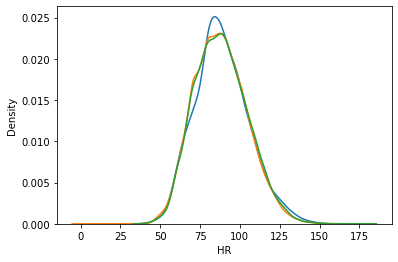

In [48]:
import seaborn as sns

# HEART RATE DISTRIBUTION AMONG CLUSTER 2,3 and 9
#plt.boxplot([clusterDct[2].table['HR'], clusterDct[3].table['HR'], clusterDct[9].table['HR']], showmeans=True, sym='')
#plt.hist(clusterDct[2].table['HR'], color='blue',bins=25)
sns.distplot(clusterDct[2].table['HR'], hist=False, kde=True, bins = 40)
sns.distplot(clusterDct[3].table['HR'], hist=False, kde=True, bins = 40)
sns.distplot(clusterDct[9].table['HR'], hist=False, kde=True, bins = 40)


/Users/ongyichong/anaconda3/lib/python3.6/site-packages/seaborn/distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).
  warnings.warn(msg, FutureWarning)
/Users/ongyichong/anaconda3/lib/python3.6/site-packages/seaborn/distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).
  warnings.warn(msg, FutureWarning)
/Users/ongyichong/anaconda3/lib/python3.6/site-packages/seaborn/distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level func

<AxesSubplot:xlabel='MeanBP', ylabel='Density'>

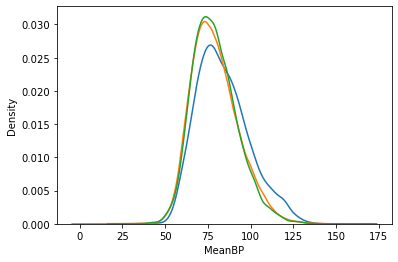

In [43]:
sns.distplot(clusterDct[2].table['MeanBP'], hist=False, kde=True, bins = 40)
sns.distplot(clusterDct[3].table['MeanBP'], hist=False, kde=True, bins = 40)
sns.distplot(clusterDct[9].table['MeanBP'], hist=False, kde=True, bins = 40)

/Users/ongyichong/anaconda3/lib/python3.6/site-packages/seaborn/distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).
  warnings.warn(msg, FutureWarning)
/Users/ongyichong/anaconda3/lib/python3.6/site-packages/seaborn/distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).
  warnings.warn(msg, FutureWarning)


<AxesSubplot:xlabel='Platelets_count', ylabel='Density'>

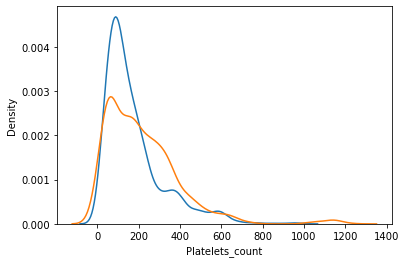

In [50]:
sns.distplot(clusterDct[4].table['Platelets_count'], hist=False, kde=True, bins = 20)
sns.distplot(clusterDct[6].table['Platelets_count'], hist=False, kde=True, bins = 20)
#sns.distplot(clusterDct[9].table['HR'], hist=False, kde=True, bins = 25)


/Users/ongyichong/anaconda3/lib/python3.6/site-packages/seaborn/distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).
  warnings.warn(msg, FutureWarning)
/Users/ongyichong/anaconda3/lib/python3.6/site-packages/seaborn/distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).
  warnings.warn(msg, FutureWarning)


<AxesSubplot:xlabel='HR', ylabel='Density'>

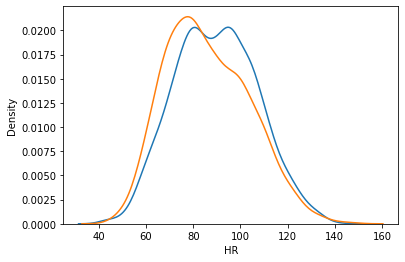

In [41]:
sns.distplot(clusterDct[4].table['HR'], hist=False, kde=True, bins = 20)
sns.distplot(clusterDct[6].table['HR'], hist=False, kde=True, bins = 20)

/Users/ongyichong/anaconda3/lib/python3.6/site-packages/seaborn/distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).
  warnings.warn(msg, FutureWarning)
/Users/ongyichong/anaconda3/lib/python3.6/site-packages/seaborn/distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).
  warnings.warn(msg, FutureWarning)


<AxesSubplot:xlabel='MeanBP', ylabel='Density'>

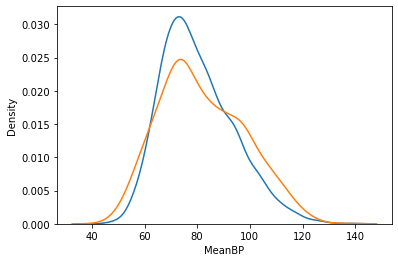

In [42]:
sns.distplot(clusterDct[4].table['MeanBP'], hist=False, kde=True, bins = 20)
sns.distplot(clusterDct[6].table['MeanBP'], hist=False, kde=True, bins = 20)

In [ ]:
# OLD CODE: CAN JUST LOOK QUALITATIVELY AT RESULTS

# iv_bins = [0, 30, 288.8, 878.5]
# iv_bins = [0, 15, 159.4, 582.15, 878.5]
# def measure_fluid_resuscitation(table):
#     fluid_amt = 0
#     ave_fluid = []
#     for i in range(len(table) - 1):
#         cur_icustay = table.iloc[i]['icustayid']
#         next_icustay = table.iloc[i+1]['icustayid']
        
#         action = table.iloc[i]['actions']
            
#         if (action % 5 == 0):
#             action = int(action / 5)
#         else:
#             action = action % 5
            
#         fluid = iv_bins[int(action)]
        
#         if cur_icustay == next_icustay:
#             fluid_amt += fluid
            
#         else:
#             ave_fluid.append(fluid_amt)
#             fluid_amt = 0
            
#     # last row   
#     action = table.iloc[-1]['actions']
    
#     if (action % 5 == 0):
#         action = int(action / 5)
#     else:
#         action = action % 5

#     fluid = iv_bins[int(action)]
#     fluid_amt += fluid
#     ave_fluid.append(fluid_amt)
#     return np.mean(ave_fluid)



In [ ]:
# Count vasopressor administrations when SOFA score < 14 between cluster 6 and 4
def count_vaso(table):
    cts = 0
    for i in range(len(table)):
        sofa = table.iloc[i]['SOFA']
        action = table.iloc[i]['actions']
        if sofa < 15:
            if action % 5 != 0:
                cts += 1
    return cts

ct_1 = count_vaso(clusterDct[6].table)
ct_2 = count_vaso(clusterDct[4].table)

In [ ]:
# when vasopressor was administered, what was the MAP of the patient ?
mean_map = []
vaso_occur = 0
t = 0
cur_icuid = clusterDct[2].table.iloc[0]['icustayid']
for i in range(len(clusterDct[2].table) - 1):
    t+=1
    next_icustay = clusterDct[2].table.iloc[i+1]['icustayid']
    row = clusterDct[2].table.iloc[i]
    action = row['actions']
    # if action has vasopressor
    #print("time step: ", t, row['SIRS'])
    if action % 5 != 0:
        print("time step: ", t, row['SIRS'] ,row['Shock_Index'], action)
        mean_map.append(row['MeanBP'])
        vaso_occur += 1
    else:
        print("time step: ", t, row['SIRS'] ,row['Shock_Index'], action)
    if cur_icuid != next_icustay:
        cur_icuid = next_icustay
        t = 0
        print("==========")
        